# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import PostHurricaneDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/post_hurricane/train_another/",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = PostHurricaneDataset(dataset_config)

## Show images from the dataset

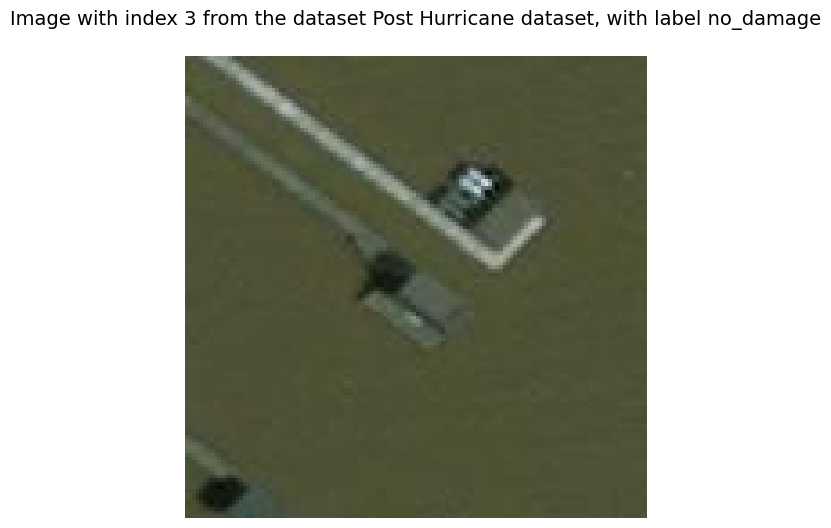

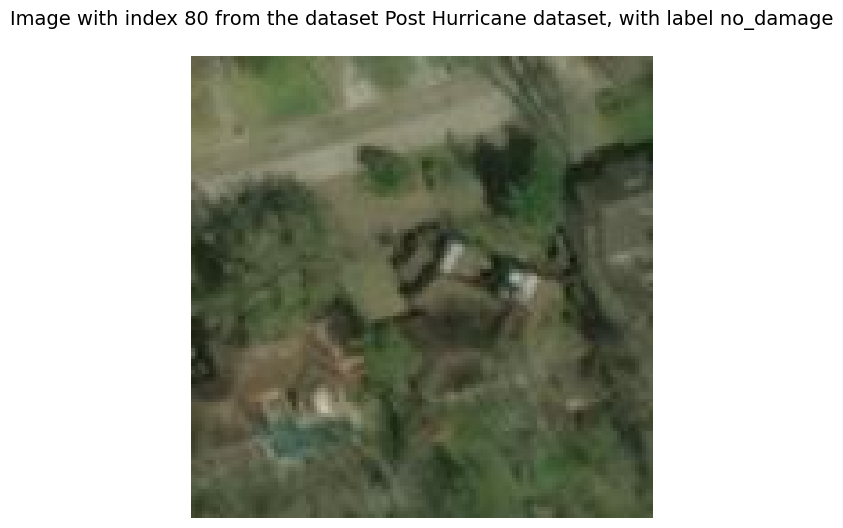

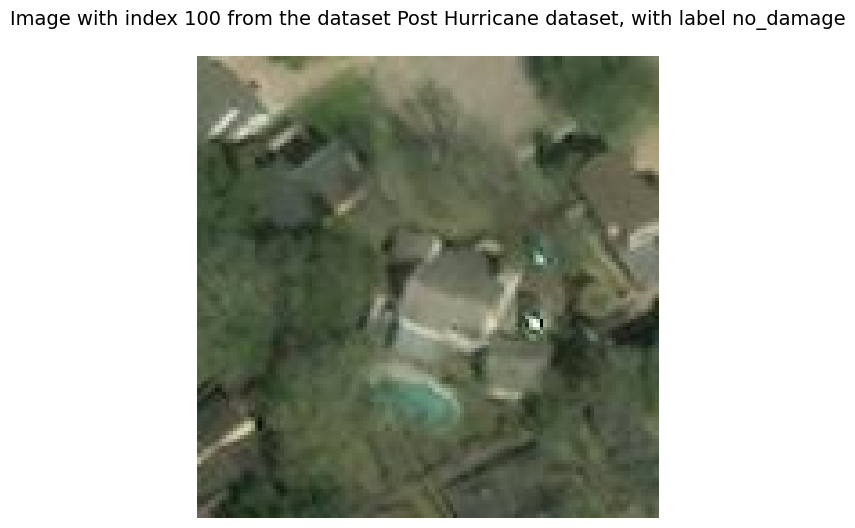

In [14]:
fig1 = dataset.show_image(3)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(100)

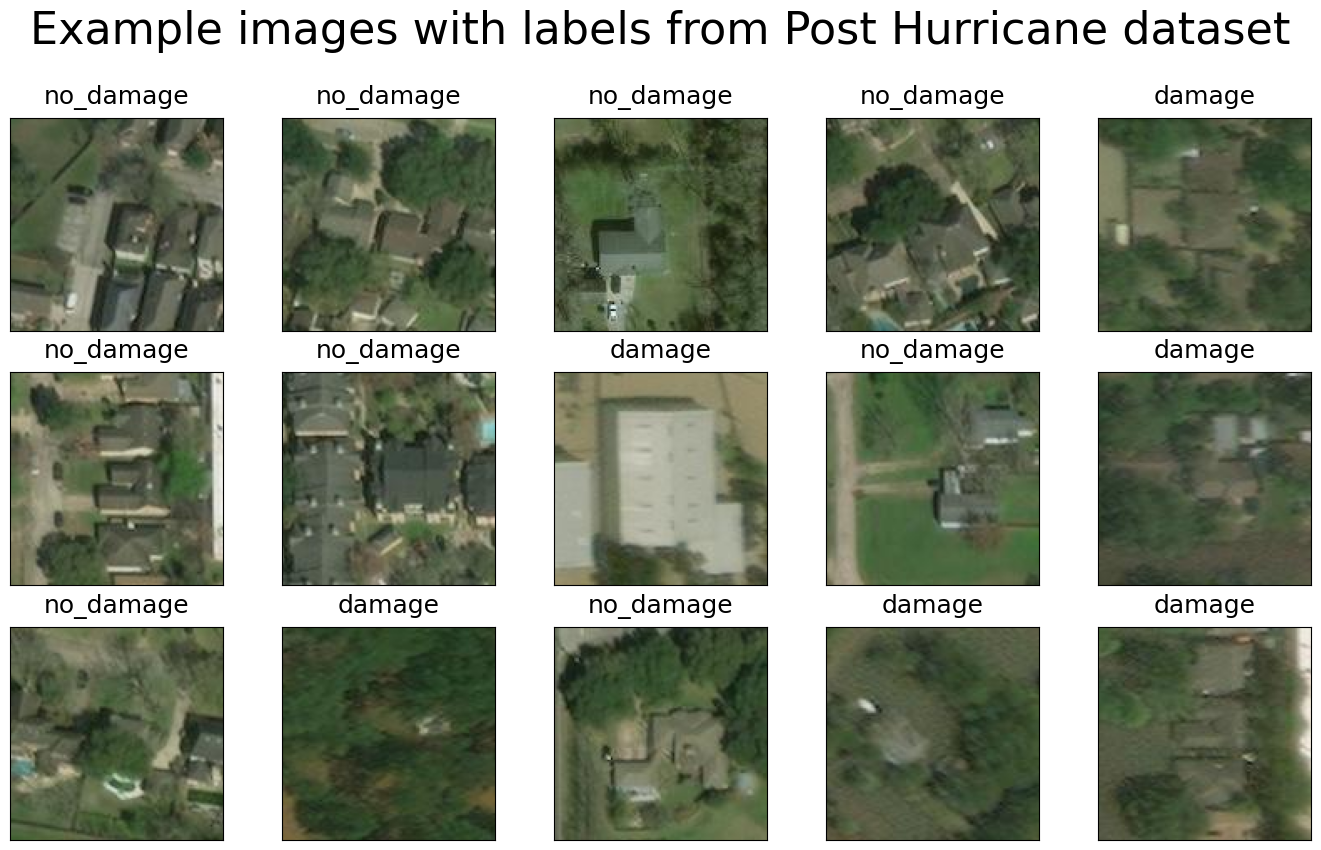

In [15]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [17]:
dataset.data_distribution_table()

,Label,Count
0,damage,5000
1,no_damage,5000


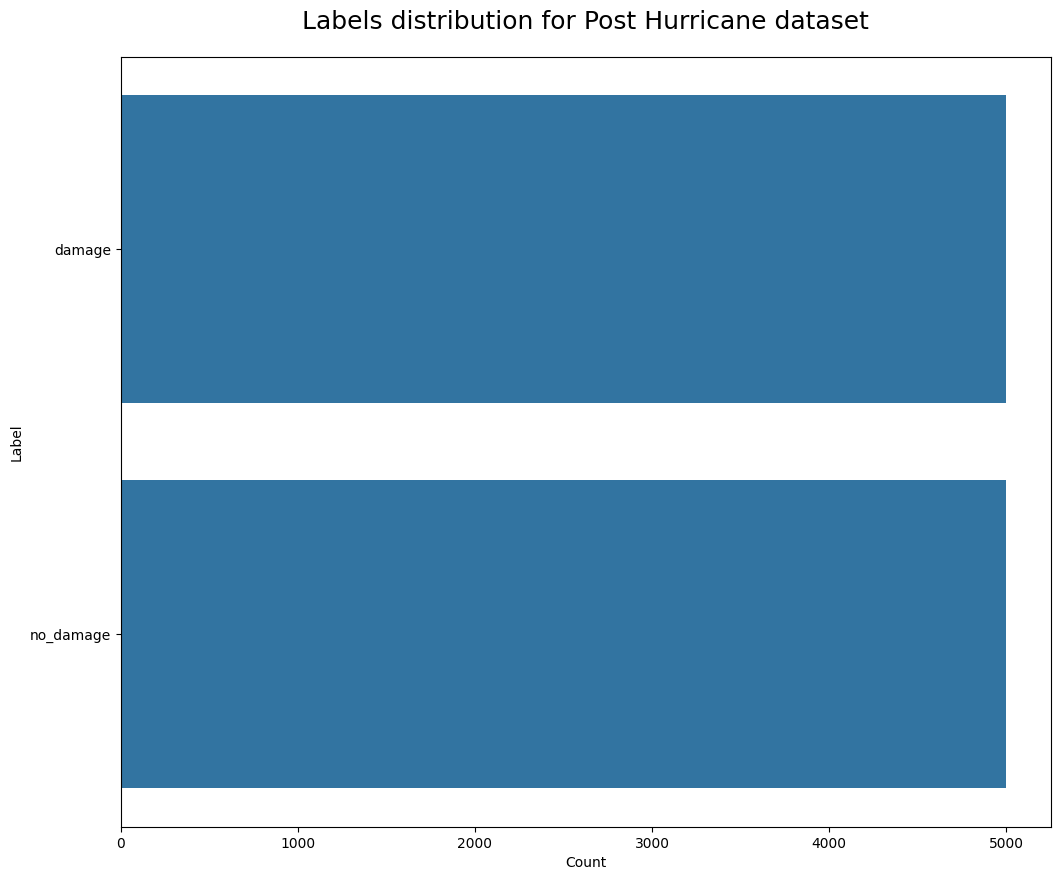

In [18]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/post_hurricane/train_another/",
}

train_dataset = PostHurricaneDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/post_hurricane/validation_another/",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = PostHurricaneDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(10000, 2000)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/post_hurricane/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-14 12:03:55,849 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-14 12:03:56,027 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [23]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-14 12:03:56,081 INFO Starting training.
training: 100%|██████████| 313/313 [04:03<00:00,  1.28it/s]
2025-05-14 12:08:00,340 INFO epoch: 1, time: 244, loss:  0.12265
testing on train set: 100%|██████████| 313/313 [01:24<00:00,  3.68it/s]
2025-05-14 12:09:27,168 INFO Accuracy:0.9884, Precision Micro:0.9884, Precision Macro:0.988405001267213, Precision Weighted:0.988405001267213, Precision per Class:[0.98684211 0.9899679 ], Recall Micro:0.9884, Recall Macro:0.9884, Recall Weighted:0.9884, Recall per Class:[0.99   0.9868], F1_score Micro:0.9883999999999994, F1_score Macro:0.9883999703039235, F1_score Weighted:0.9883999703039235, F1_score per Class:[0.98841853 0.98838141]
testing on validation set: 100%|██████████| 63/63 [00:18<00:00,  3.47it/s]
2025-05-14 12:09:45,347 INFO Accuracy:0.982, Precision Micro:0.982, Precision Macro:0.9820019280077121, Precision Weighted:0.9820019280077121, Precision per Class:[0.98296593 0.98103792], Recall Micro:0.982, Recall Macro:0.982, Recall Weight

0.034148884945415195

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/post_hurricane/test_another/",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = PostHurricaneDataset(test_dataset_config)
model_path = "./data/experiments/post_hurricane/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-14 12:59:41,250 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/post_hurricane/checkpoint.pth.tar
2025-05-14 12:59:42,124 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/post_hurricane/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 563/563 [00:59<00:00,  9.41it/s]


[{'Accuracy': 0.9804444444444445},
 {'Precision Micro': 0.9804444444444445,
  'Precision Macro': 0.9283024093049017,
  'Precision Weighted': 0.9827791624357671,
  'Precision per Class': array([0.85826087, 0.99834395])},
 {'Recall Micro': 0.9804444444444445,
  'Recall Macro': 0.9833125,
  'Recall Weighted': 0.9804444444444443,
  'Recall per Class': array([0.987   , 0.979625])},
 {'F1_score Micro': 0.9804444444444439,
  'F1_score Macro': 0.9535177169686739,
  'F1_score Weighted': 0.9810340808125264,
  'F1_score per Class': array([0.91813953, 0.9888959 ])}]

## Predictions

2025-05-14 13:00:41,978 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/post_hurricane/checkpoint.pth.tar
2025-05-14 13:00:42,622 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/post_hurricane/checkpoint.pth.tar at epoch 11


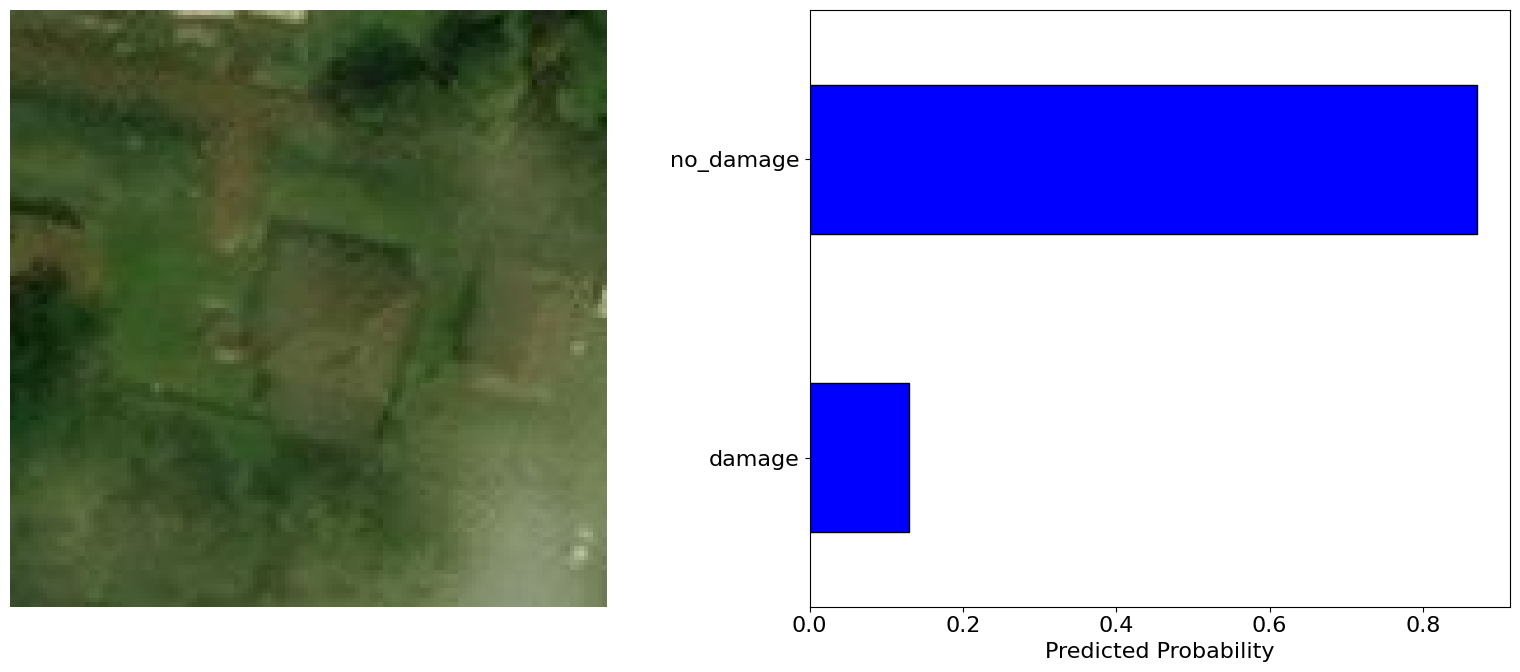

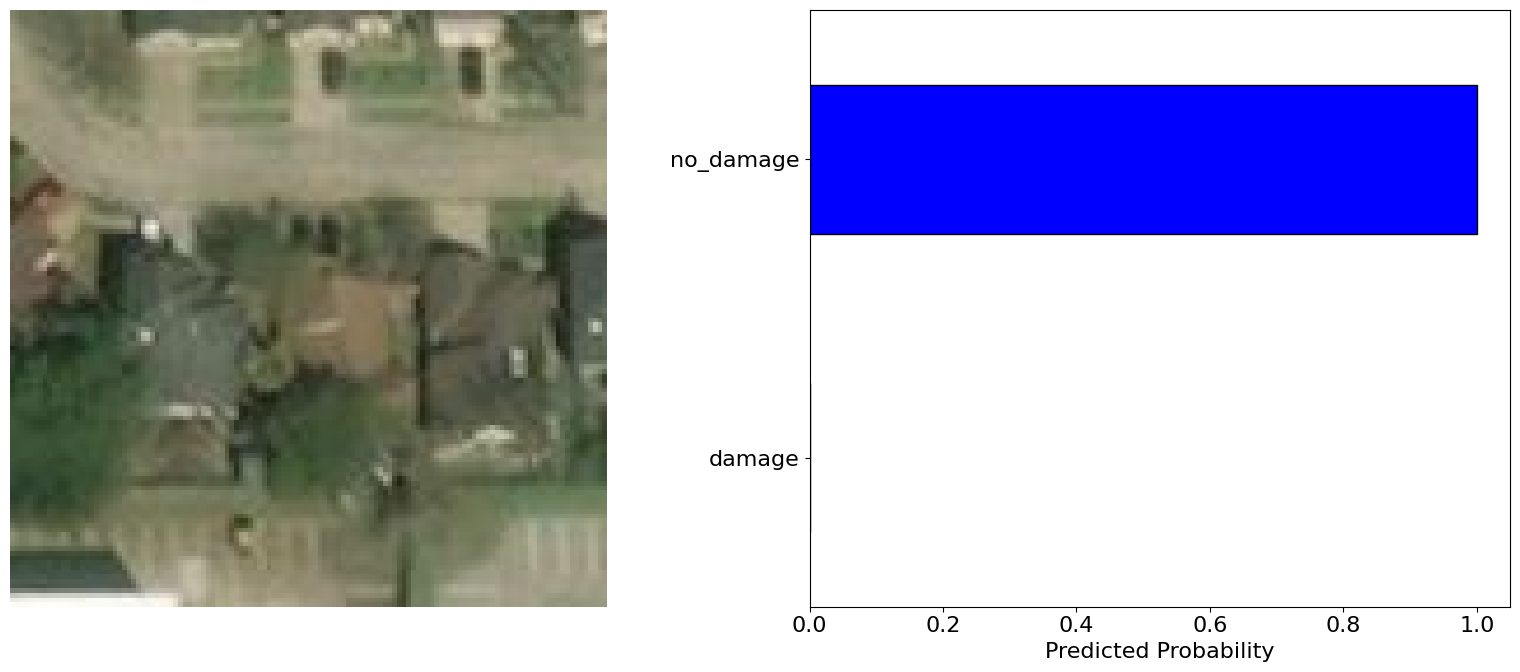

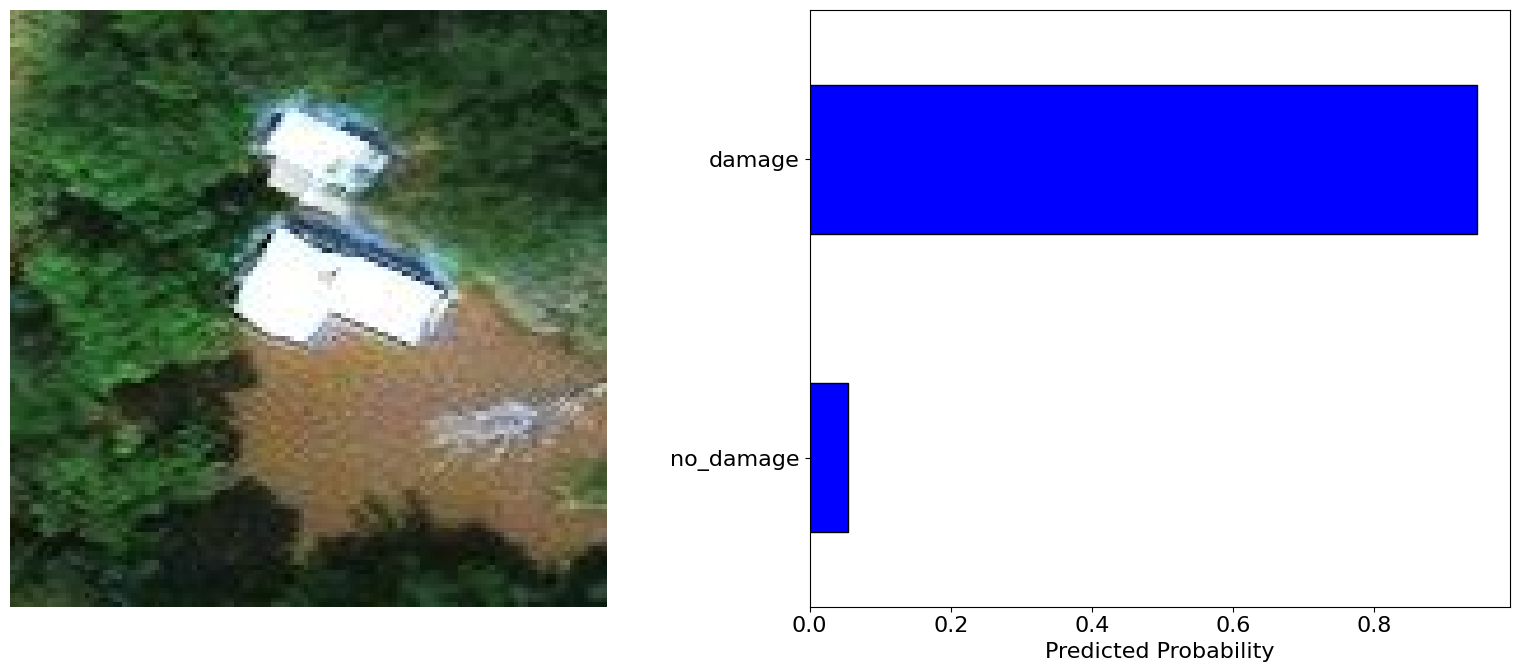

In [ ]:
labels = ["no_damage","damage"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/post_hurricane/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/post_hurricane/test_another/damage/-93.7446_30.078583000000002.jpeg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/post_hurricane/test_another/no_damage/-95.6435_29.842515999999996.jpeg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/post_hurricane/test_another/damage/-93.60851_30.661345.jpeg')
fig = model.predict_image(image, labels, transform)